In [ ]:
!pip install mxnet # GluonNLP 사용을 위한 딥러닝 프레임워크(MXNet) 설치. KoBERT 등 일부 사전학습 모델에서 필요
!pip install gluonnlp pandas tqdm # Gluon 기반 NLP 라이브러리( KoBERT 전처리나 모델 불러올 때 자주 사용) + 데이터 처리(pandas) + 진행 표시줄(tqdm) 설치
!pip install sentencepiece # Google에서 만든 토크나이저 라이브러리(KoBERT 등의 모델에서 사용하는 subword 토크나이저 설치), BERT, KoBERT 등에서 사용하는 서브워드 단위 토크나이징(예: WordPiece, BPE)에 필요
!pip install transformers # HuggingFace의 사전학습 모델(BERT, GPT 등) 라이브러리 설치
!pip install torch # PyTorch: 딥러닝 모델 구축 및 학습용 프레임워크 설치

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.0/61.0 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.1/49.1 MB 17.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.3/18.3 MB 53.7 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.0.2
    Uninstalling numpy-2.0.2:
      Successfully uninstalled numpy-2.0.2
  Attempting uninstall: graphviz
    Found existing installation: graphviz 0.20.3
    Uninstalling graphviz-0.20.3:
      Successfully uninstalled graphviz-0.20.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
thinc 8.3.6 requires numpy<3.0.0,>=2.0.0, but you have numpy 1.26.4 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 344.5/344.5 kB 11.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for gluonnlp: filename=gluonnlp-0.10.0-cp311-cp

In [ ]:
# GitHub에 있는 KoBERT 저장소의 일부 폴더(kobert_hf) 를 직접 설치하는 명령
# SK텔레콤 브레인팀에서 공개한 KoBERT 모델의 저장소
!pip install 'git+https://github.com/SKTBrain/KoBERT.git#egg=kobert_tokenizer&subdirectory=kobert_hf'

  Cloning https://github.com/SKTBrain/KoBERT.git to /tmp/pip-install-ukgl188k/kobert-tokenizer_816b73b147294cee938e5be0b753d613
  Running command git clone --filter=blob:none --quiet https://github.com/SKTBrain/KoBERT.git /tmp/pip-install-ukgl188k/kobert-tokenizer_816b73b147294cee938e5be0b753d613
  Resolved https://github.com/SKTBrain/KoBERT.git to commit 5c46b1c68e4755b54879431bd302db621f4d2f47
  Preparing metadata (setup.py) ... done
  Created wheel for kobert_tokenizer: filename=kobert_tokenizer-0.1-py3-none-any.whl size=4633 sha256=e079e4d523b429c09049304f3aeffe2fc3e3a88fda43dde6c5abf76eefcaf48b
  Stored in directory: /tmp/pip-ephem-wheel-cache-3m42wpe2/wheels/b7/95/7c/3f38b039ae9422cc4a51702b37e352d0585442cbe60285f1f2
Successfully built kobert_tokenizer


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

In [ ]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

In [ ]:
import os
import json
import random
import torch
import torch.nn as nn # 신경망 모델 구성에 필요한 클래스들
import torch.optim as optim # 최적화 알고리즘(옵티마이저) (예: SGD, Adam 등)
from torch.utils.data import Dataset, DataLoader # Dataset 클래스를 상속해 나만의 데이터셋을 만들고, DataLoader로 미니배치 단위로 나누어 학습할 수 있도록 함.
from tqdm import tqdm # 반복문의 진행 상황을 시각적으로 표시해주는 라이브러리
from transformers import BertModel, BertTokenizer, BertForSequenceClassification # HuggingFace transformers 라이브러리에서 BERT 모델과 토크나이저, 문장 분류용 모델 불러오기
from kobert_tokenizer import KoBERTTokenizer # SKT KoBERT 모델에 맞는 토큰화 방식으로 한국어 문장을 subword 단위로 나눠주는 클래스

# BertModel: 순수 BERT 구조 (classification layer 없음)
# BertTokenizer: BERT 입력 형식에 맞게 토크나이징
# BertForSequenceClassification: BERT + 분류용 Linear layer 포함된 모델

# ----- 하이퍼파라미터 -----
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu") # CUDA(GPU)가 가능하면 GPU, 아니면 CPU 설정

# ----- 토크나이저(문장을 컴퓨터가 이해할 수 있는 숫자로 바꿔주는 번역기) 및 모델 로드 -----
# KoBERT Tokenizer -> 한국어 전용 BERT 토크나이저. KoBERT는 한국어 문장 구조에 맞게 자르고 숫자로 바꾸는 역할
tokenizer = KoBERTTokenizer.from_pretrained('skt/kobert-base-v1') # 사전학습된 KoBERT 토크나이저 로드
# 이 토크나이저는 입력 문장을 KoBERT가 이해할 수 있도록 subword 단위의 토큰 ID, attention mask, token type ID로 변환해줌.

model = BertForSequenceClassification.from_pretrained('skt/kobert-base-v1', num_labels=2).to(DEVICE)
# BertForSequenceClassification: HuggingFace에서 제공하는 문장 분류용 BERT 모델 클래스
# .from_pretrained('skt/kobert-base-v1') - KoBERT 모델 구조와 가중치를 불러옴.
#  num_labels=2 -> 출력 레이블의 개수를 2개(이진 분류) 로 지정(낚시성 기사 vs 일반 기사)
# .to(DEVICE) ->  모델을 cuda(GPU)나 cpu로 올림.

# ----- 데이터 로딩 함수 -----
def load_data_from_folder(folder_path, label, max_samples=1000):
    data = [] # 결과 데이터를 담을 리스트(최종적으로 (제목, 본문, 레이블) 형태의 튜플들을 저장할 리스트)
    file_list = [f for f in os.listdir(folder_path) if f.endswith(".json")] # 해당 폴더에서 .json으로 끝나는 뉴스 파일들만 선택
    random.shuffle(file_list) # 항상 같은 순서가 아니라 무작위로 섞어서 다양한 데이터가 학습에 들어가도록 함
    file_list = file_list[:max_samples] # 섞은 리스트에서 뉴스 기사를 최대 max_samples 개수만큼만 자름

    for filename in file_list: # JSON 파일을 하나씩 순회하면서 읽음.
        try:
            with open(os.path.join(folder_path, filename), encoding='utf-8') as f: # 폴더 경로 + 파일 이름을 합쳐서 해당 파일을 UTF-8 인코딩으로 오픈
                item = json.load(f)
                title = item['labeledDataInfo']['newTitle'] # 제목 정보 추출
                content = item['sourceDataInfo']['newsContent'] # 본문 내용 추출
                data.append((title, content, label)) # (제목, 본문, 레이블) 튜플을 리스트에 저장(학습에 필요한 데이터를 하나의 튜플로 저장)
        except Exception as e:
            print(f"Error in {filename}: {e}") # 오류 발생 시 해당 파일명을 출력하고 넘어감
    return data

# ----- PyTorch Dataset 정의 -----
# <요약>
# 이 클래스는 "제목+본문+레이블" 형태의 데이터를 -> KoBERT가 학습할 수 있는 숫자 텐서 형태로 변환함.
# DataLoader에 넣으면 배치 단위로 자동으로 불러와줌.
class ClickbaitKoBERTDataset(Dataset): # PyTorch의 Dataset 클래스를 상속받아 만든 사용자 정의 데이터셋 클래스. 나중에 DataLoader와 함께 사용돼서 모델 학습에 필요한 배치를 자동으로 생성해줌.
    def __init__(self, samples, tokenizer, max_len):
        self.samples = samples  # (제목, 본문, 라벨)의 리스트
        self.tokenizer = tokenizer  # KoBERTTokenizer 인스턴스
        self.max_len = max_len # 최대 토큰 길이 (예: 512)

    def __len__(self):
        return len(self.samples) # 전체 샘플 개수 반환 (필수 구현). PyTorch가 이 데이터셋의 크기를 알 수 있도록 함.

    def __getitem__(self, idx): # 모델이 i번째 데이터를 달라고 할 때 호출됨(핵심 함수)
        title, content, label = self.samples[idx] # 해당 인덱스의 제목, 본문, 라벨 추출
        text = f"{title} [SEP] {content}" # 제목과 본문을 [SEP] 토큰으로 연결. KoBERT는 문장 분류 시 제목+본문을 [SEP]으로 구분해서 넣는 게 일반적([SEP]는 BERT 구조에서 두 문장을 구분하는 특수 토큰)
        encoding = self.tokenizer.encode_plus( # encode_plus는 입력 텍스트를 토큰 ID, attention mask 등으로 변환. padding, truncation 등으로 입력 길이를 통일.
            text,
            add_special_tokens=True, # [CLS], [SEP] 자동 추가
            max_length=self.max_len, # 최대 길이 제한
            return_token_type_ids=False, # 문장 구분 ID는 사용 안 함
            padding='max_length', # 고정 길이만큼 패딩
            truncation=True, # 너무 길면 자르기
            return_attention_mask=True, # attention_mask 반환
            return_tensors='pt' # PyTorch 텐서 형태로 반환
        )
        return { # 딥러닝 모델이 요구하는 포맷으로 데이터 1개를 반환
            'input_ids': encoding['input_ids'].squeeze(), # input_ids: 문장 토큰 ID들. 텐서 차원 [1,512] → [512]
            'attention_mask': encoding['attention_mask'].squeeze(), # attention_mask: 실제 단어는 1, 패딩은 0. 마스크도 같은 방식으로
            'label': torch.tensor(label, dtype=torch.long) # label: 0 또는 1의 정답값. 정답 레이블을 long 타입 텐서로 변환
        }

/usr/local/lib/python3.11/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/432 [00:00<?, ?B/s]

spiece.model:   0%|          | 0.00/371k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

The tokenizer class you load from this checkpoint is not the same type as the class this function is called from. It may result in unexpected tokenization. 
The tokenizer class you load from this checkpoint is 'XLNetTokenizer'. 
The class this function is called from is 'KoBERTTokenizer'.


config.json:   0%|          | 0.00/535 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/369M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/369M [00:00<?, ?B/s]

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at skt/kobert-base-v1 and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [ ]:
# ----- 실행 -----
# 폴더 경로 설정 (낚시성: 0 / 정상: 1)
fake_path = "/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/TL_Part1_Clickbait_Direct_ET"
real_path = "/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/TL_Part1_NonClickbait_Auto_ET"

fake_samples = load_data_from_folder(fake_path, 0, max_samples=3000)
real_samples = load_data_from_folder(real_path, 1, max_samples=3000)

all_samples = fake_samples + real_samples
random.shuffle(all_samples)

print(f"총 샘플 수: {len(all_samples)}")

총 샘플 수: 6000


In [ ]:
# 필요 라이브러리 임포트
from sklearn.model_selection import train_test_split       # 학습/검증 데이터 분리 함수
from sklearn.metrics import accuracy_score, f1_score       # 정확도, F1 스코어 계산 함수
from torch.utils.data import DataLoader                    # PyTorch 데이터 로더
from tqdm import tqdm                                      # 진행 상황 표시 (프로그레스 바)
import torch                                               # PyTorch 기본 패키지
import torch.nn as nn                                      # 손실 함수 등을 위한 PyTorch 신경망 모듈
import torch.optim as optim                                # 옵티마이저 모듈

# ----- 하이퍼파라미터 설정 -----
MAX_LEN = 512            # KoBERT 입력 문장의 최대 길이
BATCH_SIZE = 8           # 미니 배치 사이즈
EPOCHS = 3               # 전체 학습 반복 횟수 (에폭 수)
LEARNING_RATE = 2e-5     # AdamW 옵티마이저에 사용될 학습률

# ----- 학습/검증 데이터 분리 -----
train_samples, val_samples = train_test_split(all_samples, test_size=0.2, random_state=42)
# 전체 데이터를 80% 학습용, 20% 검증용으로 무작위 분할 (재현성을 위해 random_state 고정)

# ----- Dataset 및 DataLoader 구성 -----
train_dataset = ClickbaitKoBERTDataset(train_samples, tokenizer, MAX_LEN)
val_dataset = ClickbaitKoBERTDataset(val_samples, tokenizer, MAX_LEN)
# 사용자 정의 KoBERT 데이터셋 클래스에 따라 전처리된 Dataset 생성

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
# 학습용 데이터는 무작위 셔플, 검증용 데이터는 셔플하지 않음

# ----- 손실 함수 및 옵티마이저 설정 -----
criterion = nn.CrossEntropyLoss()
# 다중 클래스 분류 문제에 적합한 손실 함수 (KoBERT는 이진 분류라도 logits으로 처리하므로 CrossEntropy 사용 가능)

optimizer = optim.AdamW(model.parameters(), lr=LEARNING_RATE)
# BERT 계열에 적합한 AdamW 옵티마이저 사용

# ----- 학습 및 검증 루프 시작 -----
for epoch in range(EPOCHS):  # 총 EPOCHS만큼 반복
    # ==== 학습 단계 ====
    model.train()  # 모델을 학습 모드로 설정 (dropout, batchnorm 활성화)
    total_train_loss = 0  # 학습 손실 누적 변수 초기화

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        # 각 배치마다 학습 수행
        input_ids = batch['input_ids'].to(DEVICE)              # 입력 토큰 ID를 GPU로 전송
        attention_mask = batch['attention_mask'].to(DEVICE)    # Attention 마스크 전송
        labels = batch['label'].to(DEVICE)                     # 정답 레이블 전송

        optimizer.zero_grad()  # 이전 배치의 gradient 초기화
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)  # forward 연산
        loss = outputs.loss  # BERT 모델의 출력 중 loss 추출
        loss.backward()      # 역전파
        optimizer.step()     # 파라미터 업데이트

        total_train_loss += loss.item()  # 손실 누적

    # ==== 검증 단계 ====
    model.eval()  # 모델을 평가 모드로 설정 (dropout, batchnorm 비활성화)
    total_val_loss = 0  # 검증 손실 누적 변수 초기화
    all_preds, all_labels = [], []  # 예측값과 실제값 저장 리스트

    with torch.no_grad():  # 검증 시에는 gradient 계산 비활성화
        for batch in tqdm(val_loader, desc=f"Epoch {epoch+1} - Validation"):
            input_ids = batch['input_ids'].to(DEVICE)
            attention_mask = batch['attention_mask'].to(DEVICE)
            labels = batch['label'].to(DEVICE)

            outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            total_val_loss += loss.item()

            preds = torch.argmax(outputs.logits, dim=1)  # 가장 높은 logit을 가진 클래스를 예측값으로 선택
            all_preds.extend(preds.cpu().numpy())        # GPU에서 CPU로 이동 후 리스트에 저장
            all_labels.extend(labels.cpu().numpy())      # 실제 정답값도 저장

    # ==== 성능 지표 계산 ====
    val_acc = accuracy_score(all_labels, all_preds)  # 정확도 계산
    val_f1 = f1_score(all_labels, all_preds)          # F1-score 계산 (이진 분류 기준)

    # ==== 결과 출력 ====
    print(f"📘 Epoch {epoch+1}")
    print(f"🔹 Train Loss: {total_train_loss:.4f}")  # 에폭별 평균 학습 손실 출력
    print(f"🔹 Val Loss  : {total_val_loss:.4f}")    # 에폭별 평균 검증 손실 출력
    print(f"🔹 Val Acc   : {val_acc:.4f}")           # 검증 정확도 출력
    print(f"🔹 Val F1    : {val_f1:.4f}")            # 검증 F1-score 출력

Epoch 1 - Validation: 100%|██████████| 150/150 [00:34<00:00,  4.37it/s]


📘 Epoch 1
🔹 Train Loss: 62.7231
🔹 Val Loss  : 20.0813
🔹 Val Acc   : 0.9508
🔹 Val F1    : 0.9535


Epoch 2 - Validation: 100%|██████████| 150/150 [00:34<00:00,  4.36it/s]


📘 Epoch 2
🔹 Train Loss: 31.5527
🔹 Val Loss  : 13.7390
🔹 Val Acc   : 0.9700
🔹 Val F1    : 0.9702


Epoch 3 - Validation: 100%|██████████| 150/150 [00:34<00:00,  4.35it/s]

📘 Epoch 3
🔹 Train Loss: 22.4348
🔹 Val Loss  : 20.9600
🔹 Val Acc   : 0.9650
🔹 Val F1    : 0.9651


In [ ]:
torch.save(model.state_dict(), "kobert_clickbait_model.pt")

In [ ]:
# =============================
# 🔍 문장 단위 낚시성 분석 함수 추가
# =============================
def analyze_clickbait_sentences(article, tokenizer, model, device, max_len=512):
    title = article['labeledDataInfo']['newTitle']
    sentences = article['sourceDataInfo']['sentenceInfo']

    results = []

    model.eval()
    with torch.no_grad():
        for s in sentences:
            sentence = s['sentenceContent']
            text = f"{title} [SEP] {sentence}"

            encoding = tokenizer.encode_plus(
                text,
                add_special_tokens=True,
                max_length=max_len,
                return_token_type_ids=False,
                padding='max_length',
                truncation=True,
                return_attention_mask=True,
                return_tensors='pt'
            )

            input_ids = encoding['input_ids'].to(device)
            attention_mask = encoding['attention_mask'].to(device)

            outputs = model(input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()[0]

            results.append({
                'sentence': sentence,
                'clickbait_prob': probs[0],
                'non_clickbait_prob': probs[1],
                'is_clickbait': int(probs[0] > 0.5)
            })

    return results

In [ ]:
# 테스트 데이터 경로
test_fake_path = "/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/VL_Part1_Clickbait_Direct_ET"
test_real_path = "/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/VL_Part1_NonClickbait_Auto_ET"

# 테스트 샘플 로드
test_fake_samples = load_data_from_folder(test_fake_path, 0)
test_real_samples = load_data_from_folder(test_real_path, 1)

test_samples = test_fake_samples + test_real_samples
random.shuffle(test_samples)

print(f"🔍 테스트 샘플 수: {len(test_samples)}")


🔍 테스트 샘플 수: 1677


In [ ]:
test_dataset = ClickbaitKoBERTDataset(test_samples, tokenizer, MAX_LEN)
test_dataloader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

Testing: 100%|██████████| 210/210 [00:49<00:00,  4.26it/s]


📊 테스트 Classification Report
               precision    recall  f1-score   support

    Clickbait       0.88      0.98      0.93       677
Non-clickbait       0.98      0.91      0.95      1000

     accuracy                           0.94      1677
    macro avg       0.93      0.94      0.94      1677
 weighted avg       0.94      0.94      0.94      1677

F1 Score: 0.9459


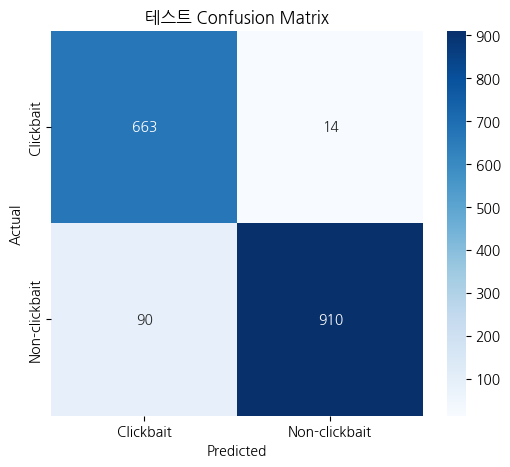

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score
import seaborn as sns
import matplotlib.pyplot as plt

model.eval() # 평가 모드로 전환
all_preds = [] # 모델의 예측값 저장 리스트
all_labels = [] # 실제 정답 라벨 저장 리스트

with torch.no_grad(): # 평가 시에는 gradient 계산 비활성화 → 속도 ↑, 메모리 ↓
    for batch in tqdm(test_dataloader, desc="Testing"): # test_dataloader: 테스트 데이터셋의 배치들을 순회
        # 각 배치의 입력과 정답 라벨을 장치(GPU or CPU)로 이동
        input_ids = batch['input_ids'].to(DEVICE)
        attention_mask = batch['attention_mask'].to(DEVICE)
        labels = batch['label'].to(DEVICE)

        outputs = model(input_ids, attention_mask=attention_mask) # 예측 수행
        logits = outputs.logits # 예측 결과의 로짓 (각 클래스에 대한 점수)
        preds = torch.argmax(logits, dim=1) # 가장 점수가 높은 클래스를 예측값으로 선택

        all_preds.extend(preds.cpu().numpy()) # 예측값을 CPU로 옮기고 리스트에 추가
        all_labels.extend(labels.cpu().numpy()) # 실제 라벨도 리스트에 추가

# 결과 출력
print("📊 테스트 Classification Report")
print(classification_report(all_labels, all_preds, target_names=["Clickbait", "Non-clickbait"]))

f1 = f1_score(all_labels, all_preds)
print(f"F1 Score: {f1:.4f}")

# Confusion Matrix
conf_matrix = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=["Clickbait", "Non-clickbait"],
            yticklabels=["Clickbait", "Non-clickbait"])
plt.title("테스트 Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# <요약>
# 테스트 데이터에 대한 예측 결과를 수집하고
# 분류 성능을 정량적으로 평가하고
# 시각화까지 한 번에 해주는 코드.

In [ ]:
json_path = "/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/자율 프로젝트/VL_Part1_Clickbait_Direct_ET/ET_M03_165214_L.json"

results = analyze_clickbait_sentences(json_path, tokenizer, model, DEVICE)

print(f"\n📰 제목: {results[0]['sentence']}")  # 첫 문장이 대표 제목일 수도 있음

for i, r in enumerate(results):
    print(f"\n[문장 {i+1}] {r['sentence']}")
    print(f"  🔹 낚시성 확률: {r['clickbait_prob']:.2f}")
    print(f"  🔹 일반 확률:   {r['non_clickbait_prob']:.2f}")
    print(f"  👉 판단: {'🧲 낚시성' if r['is_clickbait'] else '✅ 일반'}")